# IADS5 · TP integrador — Ortelana Textil
### Actividad 15 · Selección final y ajuste fino

**Integrantes del grupo:** Camila Belén Capua, Franco Salama, Juan Pablo Ruax Debruijn, Lorena Wajchman, Tomas Rossi y Miguel Ángel Tadakuma  
**Comisión:** [Completar]  
**Repositorio GitHub:** https://github.com/francosalama/paa-integrador-ortelana  
**Fecha:** 17/11/2026

> Notebook independiente. Requiere el archivo `particion_train_test.csv` (partición train/test generada por `actividad_01.ipynb`).

## Actividad 15 · Selección final y ajuste fino

**Qué se espera:** Revisá reproducibilidad de notebooks, reentrená con todos los datos de entrenamiento usando la configuración seleccionada, evaluá sobre test y cerrá README. Versioná el estado final.

**Evidencia a entregar:** Notebooks verificados; README; commit `release: modelo candidato final`; tag `v1.0`.

### TODO — Implementación libre
Desarrollá una solución propia. Organizá tantas celdas como necesites; incluí tablas y gráficos con títulos, ejes y unidades cuando correspondan. No alcanza con que el código ejecute: debe permitir comprobar las consignas.


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings("ignore", category=FutureWarning)   # avisos de versión de librerías
from sklearn.model_selection import train_test_split

RANDOM_STATE = 42
sns.set_theme(style="whitegrid")

df = pd.read_csv("ventas_historicas_ortelana_argentina.csv")

# Partición de la actividad 01: misma semilla, mismas filas de train y test
target = "Format_Reporte"
features = ["Sucursal_ID", "Tela_ID", "Año", "Metros1", "Metros2"]
train, test = train_test_split(df, test_size=0.2, stratify=df[target], random_state=RANDOM_STATE)

# Control: tiene que coincidir con la partición guardada en particion_train_test.csv
particion = pd.read_csv("particion_train_test.csv", index_col="fila")["particion"]
assert (particion[test.index] == "test").all() and (particion == "test").sum() == len(test)

X_train, X_test = train[features], test[features]
y_train, y_test = train[target], test[target]

print("Train:", X_train.shape, "| Test:", X_test.shape)


Train: (2628, 5) | Test: (657, 5)


In [2]:
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, f1_score, classification_report, ConfusionMatrixDisplay

cat_cols = ["Sucursal_ID", "Tela_ID"]
num_cols = ["Año", "Metros1", "Metros2"]

def crear_pipeline_completo(modelo):
    """Numéricas: imputar con la mediana (sin escalar). Categóricas: imputar con la moda y one-hot."""
    preprocesador = ColumnTransformer([
        ("num", Pipeline([("imputar", SimpleImputer(strategy="median"))]), num_cols),   # sin escalado: RF es invariante a la escala
        ("cat", Pipeline([("imputar", SimpleImputer(strategy="most_frequent")),
                          ("onehot", OneHotEncoder(handle_unknown="ignore", sparse_output=False))]), cat_cols),
    ], verbose_feature_names_out=False)
    return Pipeline([("preprocesamiento", preprocesador), ("modelo", modelo)])


In [3]:
# 15.1 Reproducibilidad
# La partición ya se verificó en la primera celda: coincide con particion_train_test.csv
print("Partición:", len(train), "train /", len(test), "test")

def crear_modelo_final():
    """Mejor configuración del GridSearchCV de la actividad 14 (F1 macro CV = 0.9651)."""
    return crear_pipeline_completo(RandomForestClassifier(n_estimators=100, max_depth=None, min_samples_leaf=1,
                                                          random_state=RANDOM_STATE, n_jobs=-1))

# Entrenar dos veces con la misma configuración tiene que dar exactamente las mismas predicciones
pred_a = crear_modelo_final().fit(X_train, y_train).predict(X_test)
pred_b = crear_modelo_final().fit(X_train, y_train).predict(X_test)
print("Entrenamiento determinista:", (pred_a == pred_b).all())

Partición: 2628 train / 657 test


Entrenamiento determinista: True


In [4]:
# 15.2 Reentrenamiento con TODO el conjunto de entrenamiento y la configuración seleccionada
modelo_final = crear_modelo_final()
modelo_final.fit(X_train, y_train)
print("Modelo final entrenado con", len(X_train), "registros")

Modelo final entrenado con 2628 registros


Accuracy test: 0.9711
F1 macro test: 0.9706

              precision    recall  f1-score   support

           B     0.9653    0.9521    0.9586       146
           C     0.9881    0.9651    0.9765       172
           M     0.9503    1.0000    0.9745       153
           S     0.9783    0.9677    0.9730       186

    accuracy                         0.9711       657
   macro avg     0.9705    0.9712    0.9706       657
weighted avg     0.9714    0.9711    0.9711       657



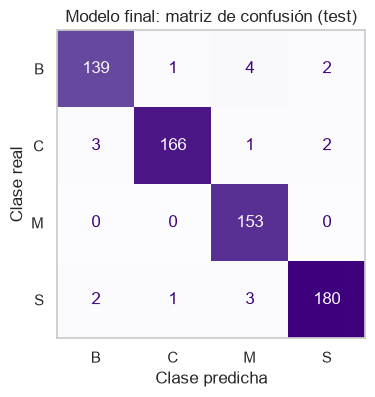

,F1 macro
"Selección: GridSearchCV (CV 5 folds, train)",0.9651
"Referencia: CV agrupada por par (actividad 13, pares nuevos)",0.6430
Final: test (una sola vez),0.9706


In [5]:
# 15.3 Evaluación final ÚNICA sobre test
pred_final = modelo_final.predict(X_test)
print("Accuracy test:", round(accuracy_score(y_test, pred_final), 4))
print("F1 macro test:", round(f1_score(y_test, pred_final, average="macro"), 4))
print()
print(classification_report(y_test, pred_final, digits=4))

fig, ax = plt.subplots(figsize=(5, 4))
ConfusionMatrixDisplay.from_predictions(y_test, pred_final, ax=ax, cmap="Purples", colorbar=False)
ax.set(title="Modelo final: matriz de confusión (test)", xlabel="Clase predicha", ylabel="Clase real")
ax.grid(False)
plt.show()

pd.DataFrame({"F1 macro": [0.9651, 0.6430, f1_score(y_test, pred_final, average="macro")]},
             index=["Selección: GridSearchCV (CV 5 folds, train)",
                    "Referencia: CV agrupada por par (actividad 13, pares nuevos)",
                    "Final: test (una sola vez)"]).round(4)

In [6]:
# 15.4 README final (archivo README.md del repositorio)
with open("README.md", encoding="utf-8") as archivo:
    print(archivo.read())

# Ortelana Textil — Clasificación de `Format_Reporte`

Trabajo práctico integrador grupal IADS5 (Procesamiento de Aprendizaje Automático).

**Integrantes:** Camila Belén Capua, Franco Salama, Juan Pablo Ruax Debruijn, Lorena Wajchman, Tomas Rossi y Miguel Ángel Tadakuma

## Problema
- **Principal:** clasificación multiclase de `Format_Reporte` (B, C, M, S) con `Sucursal_ID, Tela_ID, Año, Metros1, Metros2`.
- **Secundario (regresión):** `volumen_anual_metros` (suma anual de los metros con dato de cada fila) con `Sucursal_ID, Tela_ID, Año`, usando `Ridge(alpha=1)`. No usamos `Metros2` porque mide un período distinto según el formato (un mes en M, un semestre en S y C) y no es comparable entre filas. Las columnas `Metros1`–`Metros12` no entran como features porque son los sumandos del target.
- `Format_Reporte` es la granularidad temporal con la que la sucursal consolidó las ventas: M mensual (12 períodos), B bimestral (6), S semestral (2) y C ciclo estacional (2).
- Se excluyen `Metros3`

### Explicación del alumno/a

**Decisiones técnicas y justificación:**
- **Reproducibilidad:**
  - Regeneramos la partición con la misma semilla y comprobamos que coincide fila por fila con `particion_train_test.csv`.
  - Entrenamos dos veces la misma configuración y obtuvimos predicciones idénticas, porque todas las semillas están fijadas en 42.
  - Para la ejecución completa, el notebook corre de principio a fin sin errores con `nbconvert --execute`.
- **Reentrenamiento:** con **todo el conjunto de entrenamiento** (2.628 filas), usando la configuración elegida por GridSearchCV.
- **Evaluación final:** una única vez sobre el 20% de test.
- **README:** queda cerrado, con el problema, la estructura, la reproducción, los resultados finales, las limitaciones y las versiones.

**Interpretación de los resultados:**
- **Resultado final en test:** **F1 macro = 0,9706** y **accuracy = 0,9711** sobre 657 registros, en línea con la estimación de CV (0,965). No hay señales de sobreajuste a la validación, pero ese 0,97 vale para pares (Sucursal, Tela) ya vistos: con la CV agrupada por par de la Actividad 13, el mismo pipeline obtiene 0,643.
- **Por clase:**
  - B: F1 0,959 (recall 0,952).
  - C: 0,977.
  - M: 0,975 (recall 1,00).
  - S: 0,973.
- **Errores:** son 19 de 657 y repiten el patrón del análisis fuera de fold: M tiene recall 1,00 pero recibe falsos positivos de otras clases (precision 0,95).

**Pregunta de análisis:** ¿Qué resultados son finales y cuáles provinieron de la búsqueda de modelos?
- **Finales:** solo las métricas de la celda 15.3 (F1 macro 0,9706, accuracy 0,9711, reporte por clase y matriz de confusión). Corresponden al modelo final reentrenado con todo el train y evaluado en test una sola vez después de cerrar todas las decisiones.
- **De la búsqueda (no son estimaciones imparciales):**
  - Las medias de CV de las actividades 7–14, incluido el 0,9651 de GridSearchCV, que es el máximo entre 27 candidatos y por eso es levemente optimista.
  - Las métricas de test "históricas" de las actividades 2–13. Las pide el enunciado, pero al consultarlas repetidamente el test dejó de ser completamente ajeno a las decisiones.
- **Para mitigar ese sesgo:** elegimos el modelo y los hiperparámetros solo con CV.

**Limitaciones o mejoras posibles:**
- El 0,97 vale para registros de pares (Sucursal, Tela) ya conocidos y años dentro del rango 2016–2025. Para sucursales o telas nuevas, la estimación es la de la CV agrupada (~0,64): el clasificador no generaliza a pares nuevos y no debe pasar a producción para ese uso.
- Para el uso productivo convendría reentrenar con train + test una vez cerrada la evaluación.

### Comentarios del docente

[Espacio breve para observaciones sobre esta actividad: aciertos, correcciones o sugerencias.]
